In [15]:
import pandas as pd
from sklearn.metrics import (
    mean_absolute_error, 
    mean_squared_error, 
    r2_score,
    explained_variance_score,
    mean_absolute_percentage_error
)
from sklearn.model_selection import train_test_split
import numpy as np
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.feature_selection import SelectFromModel
from sklearn.model_selection import cross_val_score
from sklearn.metrics import mean_squared_error
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor
from matplotlib import pyplot as plt

In [4]:
data = pd.read_csv('data_x_selection/AirQualityUCI_top20features.csv')
data.head()

,CO(GT)_Std_24h,Benzene_Weather_Index,CO(GT)_MA_24h,CO(GT)_Lag3h,NO2(GT),PT08.S1(CO),CO(GT)_Volatility,CO(GT)_Std_6h,PT08.S3(NOx)_Accuracy,CO(GT)_Change1h,...,NOx(GT),CO(GT)_Change3h,CO_Temp_Interaction,CO(GT)_Trend_24h,CO_Level_Encoded,CO_NO2_Ratio,CO(GT)_MA_3h,PT08.S1(CO)_Accuracy,CO(GT)_Rate1h,CO(GT)
0,0.406539,0.026837,2.378917,2.2,169.0,1496.0,0.112998,0.299444,4.779070,0.6,...,172.0,0.6,75.88,0.421083,0,0.016568,2.566667,534.285523,0.272727,2.8
1,0.401711,0.023515,2.401080,2.3,149.0,1409.0,0.097875,0.275681,5.259036,-0.1,...,166.0,0.4,69.66,0.298920,0,0.018121,3.066667,521.851659,-0.035714,2.7
2,0.585604,0.034880,2.431026,2.2,156.0,1513.0,0.206704,0.575326,3.570093,1.0,...,214.0,1.5,85.10,1.268974,0,0.023718,3.200000,408.918808,0.370370,3.7
3,0.594567,0.018208,2.472405,2.8,135.0,1430.0,0.208748,0.563619,4.573034,-0.5,...,178.0,0.4,51.20,0.727595,0,0.023704,3.000000,446.874860,-0.135135,3.2
4,0.581735,0.012290,2.519114,2.7,121.0,1333.0,0.235599,0.604704,6.860465,-1.1,...,129.0,-0.6,30.45,-0.419114,0,0.017355,2.333333,634.761602,-0.343750,2.1


In [12]:
# 1. Split the data into features and target variable
X = data.drop(columns=['CO(GT)'])
y = data['CO(GT)']

# 2. Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [6]:
print("Shape of X:", X.shape)
print("Shape of y:", y.shape)

Shape of X: (6789, 20)
Shape of y: (6789,)


In [13]:
print("Shape of X_train:", X_train.shape)
print("Shape of X_test:", X_test.shape)
print("Shape of y_train:", y_train.shape)
print("Shape of y_test:", y_test.shape)

Shape of X_train: (5431, 20)
Shape of X_test: (1358, 20)
Shape of y_train: (5431,)
Shape of y_test: (1358,)


Comparaison détaillée des modèles :


,MAE,RMSE,R2,Explained Variance,MAPE
Model,,,,,
Ridge,0.000376,0.000502,1.000000,1.000000,0.000324
Lasso,0.244308,0.350915,0.805567,0.805851,0.209682
ElasticNet,0.206254,0.294491,0.863067,0.863254,0.177280
RandomForest,0.052397,0.085411,0.988482,0.988517,0.036966
GradientBoosting,0.029820,0.044036,0.996938,0.996945,0.020790
XGBoost,0.031980,0.047755,0.996399,0.996406,0.022340


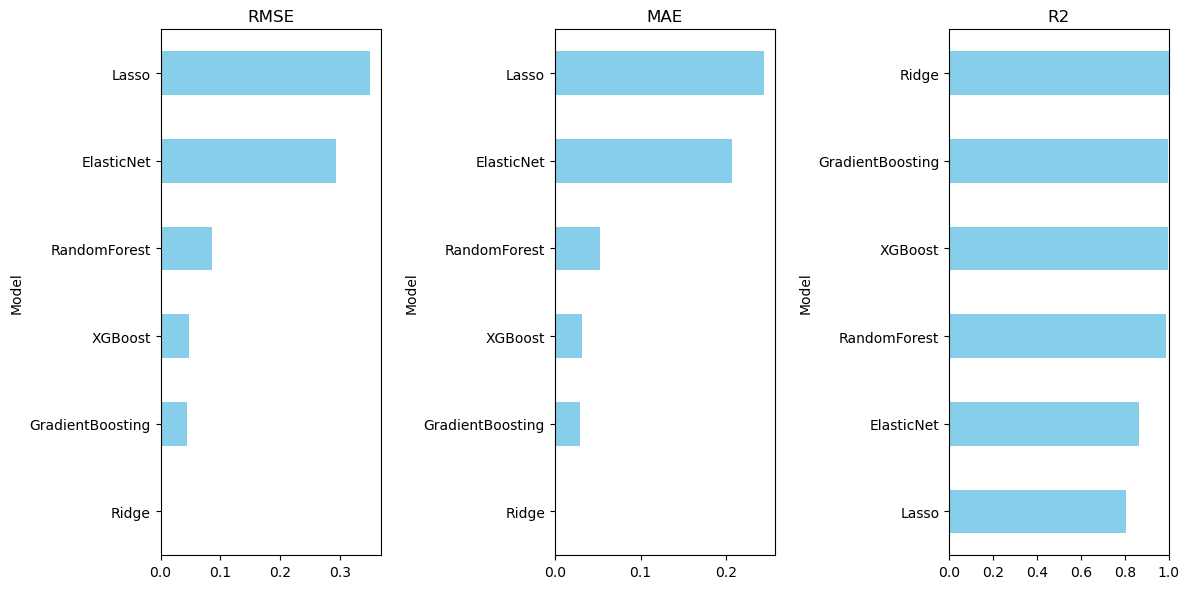

In [16]:
# 2. Dictionnaire des métriques à calculer
metrics = {
    'MAE': mean_absolute_error,
    'RMSE': lambda y, y_pred: np.sqrt(mean_squared_error(y, y_pred)),
    'R2': r2_score,
    'Explained Variance': explained_variance_score,
    'MAPE': mean_absolute_percentage_error
}

models = {
    'Ridge': Ridge(alpha=1.0),
    'Lasso': Lasso(alpha=0.1),  # Alpha plus bas pour plus de sélectivité
    'ElasticNet': ElasticNet(alpha=0.1, l1_ratio=0.7)  # Mix L1/L2
}
# 1. Ajout des modèles d'ensemble
models.update({
    'RandomForest': RandomForestRegressor(n_estimators=100, max_depth=5, random_state=42),
    'GradientBoosting': GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, max_depth=3),
    'XGBoost': XGBRegressor(n_estimators=100, learning_rate=0.1, max_depth=3)
})

# 3. Entraînement et évaluation
results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    
    # Calcul de toutes les métriques
    model_metrics = {'Model': name}
    for metric_name, metric_func in metrics.items():
        try:
            model_metrics[metric_name] = metric_func(y_test, y_pred)
        except Exception as e:
            model_metrics[metric_name] = f"Error: {str(e)}"
    
    results.append(model_metrics)

# 4. DataFrame des résultats
results_df = pd.DataFrame(results).set_index('Model')
print("Comparaison détaillée des modèles :")
display(results_df.style.background_gradient(cmap='Blues', subset=['R2', 'Explained Variance'])\
                       .background_gradient(cmap='Reds_r', subset=['MAE', 'RMSE', 'MAPE']))

# 5. Visualisation comparative
plt.figure(figsize=(12, 6))
metrics_to_plot = ['RMSE', 'MAE', 'R2']
for i, metric in enumerate(metrics_to_plot, 1):
    plt.subplot(1, 3, i)
    results_df[metric].sort_values().plot(kind='barh', color='skyblue')
    plt.title(metric)
    if metric == 'R2':
        plt.xlim(0, 1)  # R2 est entre 0 et 1
plt.tight_layout()
plt.show()

### Analyse Globale
### Meilleur modèle :
* Gradient Boosting (MAE=0.0298, R²=0.997) domine clairement, suivi de près par XGBoost.
### Pire modèle : Lasso (R²=0.806), qui semble sous-performer significativement.

### Overfitting suspect :
Le Ridge (MAE=0.0004, R²=1.0) montre des résultats trop parfaits → Vérifiez si :

* Fuite de données (target dans les features ?)

* Problème de split train/test (test set trop petit ?)